# Recipie Identifier 
This model is designed to predict the mixture composition of a vial by estimating the amounts of each component (t100_ml, t200_ml, and t400_ml) directly from image data. The model uses visual features from the filling process to infer the proportion of each solution present in the final mixture.

In [169]:
from pathlib import Path
import pandas as pd

csv_path = Path("video5_frame_labels.csv")
df = pd.read_csv(csv_path)

In [170]:
from zipfile import ZipFile

with ZipFile("images-20261021T001554Z-1-001.zip", "r") as z:
    z.extractall("images")

print("Done!")

Done!


In [171]:
import seaborn as sns
import matplotlib.pyplot as plt
import sys
from PIL import Image
from pathlib import Path
from zipfile import ZipFile
from torchvision import transforms
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
import torch
import torch.nn as nn
from torchvision.models import resnet18
import numpy as np
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score
from sklearn.linear_model import LinearRegression

In [172]:

labels_path = Path("video5_frame_labels.csv")
images_zip_path = Path("images-20261021T001554Z-1-001.zip")

frame_labels = pd.read_csv(labels_path)

with ZipFile(images_zip_path) as archive:
    image_members = [
        name for name in archive.namelist()
        if Path(name).suffix.lower() in {".jpg", ".jpeg", ".png"}
    ]

image_files = pd.DataFrame({
    "filename": [Path(name).name for name in image_members],
    "image_in_zip": image_members,
})

paired_images = frame_labels.merge(
    image_files,
    on="filename",
    how="left",
    validate="one_to_one",
    indicator=True,
)

matched_count = (paired_images["_merge"] == "both").sum()
print(f"Matched {matched_count} of {len(frame_labels)} labeled frames to images in the ZIP.")
print(f"Labeled frames with no image match: {(paired_images['_merge'] == 'left_only').sum()}")

display(
    paired_images[["filename", "image_in_zip", "in_fill", "vial", "recipe_id", "type"]]
    .head(10)
)

Matched 845 of 845 labeled frames to images in the ZIP.
Labeled frames with no image match: 0


,filename,image_in_zip,in_fill,vial,recipe_id,type
0,vial_fill_20260923_194709_622176.jpg,images/vial_fill_20260923_194709_622176.jpg,0,NaN,NaN,between_fills
1,vial_fill_20260923_194711_630429.jpg,images/vial_fill_20260923_194711_630429.jpg,1,1.0,5.0,Triple
2,vial_fill_20260923_194713_645810.jpg,images/vial_fill_20260923_194713_645810.jpg,1,1.0,5.0,Triple
3,vial_fill_20260923_194715_654285.jpg,images/vial_fill_20260923_194715_654285.jpg,1,1.0,5.0,Triple
4,vial_fill_20260923_194717_665803.jpg,images/vial_fill_20260923_194717_665803.jpg,1,1.0,5.0,Triple
5,vial_fill_20260923_194719_681338.jpg,images/vial_fill_20260923_194719_681338.jpg,1,1.0,5.0,Triple
6,vial_fill_20260923_194721_685912.jpg,images/vial_fill_20260923_194721_685912.jpg,1,1.0,5.0,Triple
7,vial_fill_20260923_194723_697664.jpg,images/vial_fill_20260923_194723_697664.jpg,1,1.0,5.0,Triple
8,vial_fill_20260923_194725_707479.jpg,images/vial_fill_20260923_194725_707479.jpg,1,1.0,5.0,Triple
9,vial_fill_20260923_194727_719609.jpg,images/vial_fill_20260923_194727_719609.jpg,1,1.0,5.0,Triple


## Clean data

In [173]:
#takes away the Nan cells
critical_cols = [
    "vial",
    "recipe_id",
    "total_ml"
]

df = df.dropna(subset=critical_cols)
print("After dropna:", df.shape)
print(df.groupby("recipe_id")["vial"].nunique())

After dropna: (509, 13)
recipe_id
5.0     3
6.0     3
7.0     3
8.0     3
9.0     3
10.0    3
11.0    3
12.0    3
13.0    3
14.0    3
Name: vial, dtype: int64


In [174]:
#Changing Nan fill vials with zero 
volume_cols = ["t100_ml", "t200_ml", "t400_ml"]

df[volume_cols] = df[volume_cols].fillna(0)

In [175]:
#Frames only durring filling
df = df[df["in_fill"] == 1].reset_index(drop=True)

In [176]:
#Keeping final frames
df = (
    df.sort_values("timestamp")
      .groupby(["recipe_id", "vial"])
      .tail(10)
      .reset_index(drop=True)
)
print("After dropna:", df.shape)

After dropna: (300, 13)


In [177]:
df["r100"] = df["t100_ml"] / df["total_ml"]
df["r200"] = df["t200_ml"] / df["total_ml"]
df["r400"] = df["t400_ml"] / df["total_ml"]

ratio_sum = (
    df["r100"] +
    df["r200"] +
    df["r400"]
)

print(ratio_sum.describe())

count    300.0
mean       1.0
std        0.0
min        1.0
25%        1.0
50%        1.0
75%        1.0
max        1.0
dtype: float64


In [178]:
df.to_csv(
    "cleaned_regression_dataset.csv",
    index=False
)

## 3-Fold Vial Splits No image cleaning

In [179]:
print(sorted(df["vial"].unique()))


[np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0), np.float64(11.0), np.float64(12.0), np.float64(13.0), np.float64(14.0), np.float64(15.0), np.float64(16.0), np.float64(17.0), np.float64(18.0), np.float64(19.0), np.float64(20.0), np.float64(21.0), np.float64(22.0), np.float64(23.0), np.float64(24.0), np.float64(25.0), np.float64(26.0), np.float64(27.0), np.float64(28.0), np.float64(29.0), np.float64(30.0)]


In [180]:
for recipe in sorted(df["recipe_id"].unique()):
    vials = sorted(
        df[df["recipe_id"] == recipe]["vial"].unique()
    )
    print(f"Recipe {recipe}: {vials}")

Recipe 5.0: [np.float64(1.0), np.float64(2.0), np.float64(3.0)]
Recipe 6.0: [np.float64(4.0), np.float64(5.0), np.float64(6.0)]
Recipe 7.0: [np.float64(7.0), np.float64(8.0), np.float64(9.0)]
Recipe 8.0: [np.float64(10.0), np.float64(11.0), np.float64(12.0)]
Recipe 9.0: [np.float64(13.0), np.float64(14.0), np.float64(15.0)]
Recipe 10.0: [np.float64(16.0), np.float64(17.0), np.float64(18.0)]
Recipe 11.0: [np.float64(19.0), np.float64(20.0), np.float64(21.0)]
Recipe 12.0: [np.float64(22.0), np.float64(23.0), np.float64(24.0)]
Recipe 13.0: [np.float64(25.0), np.float64(26.0), np.float64(27.0)]
Recipe 14.0: [np.float64(28.0), np.float64(29.0), np.float64(30.0)]


In [181]:
recipes = sorted(df["recipe_id"].unique())

folds = []

for fold_idx in range(3):

    train_parts = []
    test_parts = []

    for recipe in recipes:

        recipe_df = df[df["recipe_id"] == recipe]

        recipe_vials = sorted(
            recipe_df["vial"].unique()
        )

        test_vial = recipe_vials[fold_idx]

        train_parts.append(
            recipe_df[
                recipe_df["vial"] != test_vial
            ]
        )

        test_parts.append(
            recipe_df[
                recipe_df["vial"] == test_vial
            ]
        )

    train_df = pd.concat(train_parts).reset_index(drop=True)
    test_df = pd.concat(test_parts).reset_index(drop=True)

    folds.append((train_df, test_df))

In [182]:
for i, (train_df, test_df) in enumerate(folds):

    print(
        f"Fold {i+1}: "
        f"Train={len(train_df)}, "
        f"Test={len(test_df)}"
    )

Fold 1: Train=200, Test=100
Fold 2: Train=200, Test=100
Fold 3: Train=200, Test=100


### Building regresion DataSet

In [183]:
for i, (train_df, test_df) in enumerate(folds):
    print(
        f"Fold {i+1} "
        f"Train recipes={train_df['recipe_id'].nunique()} "
        f"Test recipes={test_df['recipe_id'].nunique()}"
    )

Fold 1 Train recipes=10 Test recipes=10
Fold 2 Train recipes=10 Test recipes=10
Fold 3 Train recipes=10 Test recipes=10


In [184]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [185]:
class MixDataset(Dataset):

    def __init__(self, dataframe, image_root, transform=None):

        self.df = dataframe.reset_index(drop=True)
        self.image_root = Path(image_root)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image_path = self.image_root / row["filename"]

        image = Image.open(image_path).convert("RGB")

        target = np.array([
            row["r100"],
            row["r200"],
            row["r400"]
        ], dtype=np.float32)

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(target)

Fold 1

In [186]:
train_df, test_df = folds[0]

In [187]:
#Creating data sets
train_dataset = MixDataset(
    train_df,
    "images/images",
    train_transform
)

test_dataset = MixDataset(
    test_df,
    "images/images",
    test_transform
)

In [188]:
#Creating Data Loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False
)

In [189]:
images, targets = next(iter(train_loader))

print(images.shape)
print(targets.shape)

print(targets[:5])

torch.Size([16, 3, 224, 224])
torch.Size([16, 3])
tensor([[0.2857, 0.0000, 0.7143],
        [0.1429, 0.1429, 0.7143],
        [0.2857, 0.0000, 0.7143],
        [0.1250, 0.4375, 0.4375],
        [0.8571, 0.0000, 0.1429]])


## The Regression ResNet18

In [190]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(device)

cpu


In [192]:
resnet_model = resnet18(weights="DEFAULT")

resnet_model.fc = nn.Linear(
    resnet_model.fc.in_features,
    3
)

resnet_model = resnet_model.to(device)

In [193]:
print(resnet_model.fc)

Linear(in_features=512, out_features=3, bias=True)


In [194]:
criterion = nn.MSELoss()

In [195]:
optimizer = torch.optim.Adam(
    resnet_model.parameters(),
    lr=1e-4
)


In [196]:
images, targets = next(iter(train_loader))

images = images.to(device)

outputs = resnet_model(images)

print(outputs.shape)

torch.Size([16, 3])


In [198]:
num_epochs = 10

for epoch in range(num_epochs):

    resnet_model.train()

    running_loss = 0.0

    for images, targets in train_loader:

        images = images.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()

        outputs = resnet_model(images)

        loss = criterion(outputs, targets)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    print(
        f"Epoch {epoch+1}/{num_epochs} "
        f"Loss: {running_loss/len(train_loader):.4f}"
    )

Epoch 1/10 Loss: 0.2853
Epoch 2/10 Loss: 0.0562
Epoch 3/10 Loss: 0.0298
Epoch 4/10 Loss: 0.0179
Epoch 5/10 Loss: 0.0140
Epoch 6/10 Loss: 0.0114
Epoch 7/10 Loss: 0.0148
Epoch 8/10 Loss: 0.0110
Epoch 9/10 Loss: 0.0095
Epoch 10/10 Loss: 0.0052


## Results 

In [201]:
resnet_model.eval()

preds = []
truths = []

with torch.no_grad():

    for images, targets in test_loader:

        images = images.to(device)

        outputs = resnet_model(images)

        preds.append(
            outputs.cpu().numpy()
        )

        truths.append(
            targets.numpy()
        )

preds = np.vstack(preds)
truths = np.vstack(truths)

In [202]:
mae = mean_absolute_error(
    truths,
    preds
)

print("MAE:", mae)

MAE: 0.18268294632434845


In [203]:
r2 = r2_score(
    truths,
    preds
)

print("R²:", r2)

R²: 0.1453215479850769


In [204]:
print(truths[:10])

print(preds[:10])

[[0.33333334 0.33333334 0.33333334]
 [0.33333334 0.33333334 0.33333334]
 [0.33333334 0.33333334 0.33333334]
 [0.33333334 0.33333334 0.33333334]
 [0.33333334 0.33333334 0.33333334]
 [0.33333334 0.33333334 0.33333334]
 [0.33333334 0.33333334 0.33333334]
 [0.33333334 0.33333334 0.33333334]
 [0.33333334 0.33333334 0.33333334]
 [0.33333334 0.33333334 0.33333334]]
[[0.4676827  0.2774895  0.3047985 ]
 [0.47830105 0.23776463 0.32596773]
 [0.46417952 0.23497549 0.35567486]
 [0.40845895 0.2848797  0.3114786 ]
 [0.44139937 0.32300875 0.29025728]
 [0.47819716 0.24731597 0.38224566]
 [0.50260043 0.19102511 0.33561882]
 [0.4714113  0.28164113 0.29479125]
 [0.47228193 0.31028542 0.29599866]
 [0.49282095 0.2595145  0.26573572]]


In [88]:
print(
    df.groupby("recipe_id")[
        ["r100", "r200", "r400"]
    ].first()
)

               r100      r200      r400
recipe_id                              
5.0        0.333333  0.333333  0.333333
6.0        0.750000  0.250000  0.000000
7.0        0.285714  0.000000  0.714286
8.0        0.333333  0.333333  0.333333
9.0        0.125000  0.437500  0.437500
10.0       0.600000  0.200000  0.200000
11.0       0.142857  0.142857  0.714286
12.0       0.142857  0.714286  0.142857
13.0       0.000000  0.714286  0.285714
14.0       0.857143  0.000000  0.142857


In [89]:
print(preds.mean(axis=0))
print(preds.std(axis=0))

[0.46217453 0.27092308 0.2986125 ]
[0.18466738 0.15844087 0.10040475]


The first fold demonstrates that the model can extract some information about mixture composition from the images, but substantial room for improvement remains. Importantly, the vial-based evaluation provides a more honest assessment of real-world generalization than the original recipe classification approach and establishes a baseline for further experimentation

In [95]:
fold_mae = []
fold_r2 = []

for fold_num in range(3):

    train_df, test_df = folds[fold_num]

    train_dataset = MixDataset(
        train_df,
        "images/images",
        train_transform
    )

    test_dataset = MixDataset(
        test_df,
        "images/images",
        test_transform
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=16,
        shuffle=True
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=16,
        shuffle=False
    )

    resnet_model = resnet18(weights="DEFAULT")

    resnet_model.fc = nn.Linear(
        resnet_model.fc.in_features,
        3
    )

    resnet_model = resnet_model.to(device)

    criterion = nn.MSELoss()

    optimizer = torch.optim.Adam(
        resnet_model.parameters(),
        lr=1e-4
    )

    # ---------- TRAIN ----------
    num_epochs = 10

    for epoch in range(num_epochs):

        resnet_model.train()

        for images, targets in train_loader:

            images = images.to(device)
            targets = targets.to(device)

            optimizer.zero_grad()

            outputs = resnet_model(images)

            loss = criterion(outputs, targets)

            loss.backward()

            optimizer.step()

    # ---------- EVALUATE ----------
    resnet_model.eval()

    preds = []
    truths = []

    with torch.no_grad():

        for images, targets in test_loader:

            images = images.to(device)

            outputs = resnet_model(images)

            preds.append(
                outputs.cpu().numpy()
            )

            truths.append(
                targets.numpy()
            )

    preds = np.vstack(preds)
    truths = np.vstack(truths)

    mae = mean_absolute_error(
        truths,
        preds
    )

    r2 = r2_score(
        truths,
        preds
    )

    fold_mae.append(mae)
    fold_r2.append(r2)

    print(
        f"Fold {fold_num+1}: "
        f"MAE={mae:.4f}, "
        f"R²={r2:.4f}"
    )

print("\nOverall Results")
print(f"Mean MAE: {np.mean(fold_mae):.4f}")
print(f"Std MAE : {np.std(fold_mae):.4f}")

print(f"Mean R² : {np.mean(fold_r2):.4f}")
print(f"Std R²  : {np.std(fold_r2):.4f}")

Fold 1: MAE=0.1910, R²=-0.0391
Fold 2: MAE=0.1583, R²=0.2892
Fold 3: MAE=0.2442, R²=-0.4439

Overall Results
Mean MAE: 0.1978
Std MAE : 0.0354
Mean R² : -0.0646
Std R²  : 0.2998



The baseline model was able to learn some relationship between image appearance and mixture composition, but performance remained modest. In some cases, the model generalized reasonably well to unseen vials, while in others it struggled to outperform a simple mean prediction.

This behavior is not unexpected because the model was trained on full camera images containing:

Multiple vials
Machine hardware
Labels and barcodes
Background structures
Timestamp information

Much of the image content is unrelated to the liquid composition and may distract the network from the visual signal of interest.

Additionally, the dataset is relatively small for deep learning, with only 200 training images available per fold.

## Cleaning Images (Only Cropping)

In [142]:
def preprocess_image(image):

    image = image.crop(
        (
            272,  # left
            270,  # top
            352,  # right
            415   # bottom
        )
    )

    return image

In [143]:
class MixDataset(Dataset):

    def __init__(self, dataframe, image_root, transform=None):

        self.df = dataframe.reset_index(drop=True)
        self.image_root = Path(image_root)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image_path = self.image_root / row["filename"]

        image = Image.open(image_path).convert("RGB")

        # Crop to vial region
        image = preprocess_image(image)

        target = np.array([
            row["r100"],
            row["r200"],
            row["r400"]
        ], dtype=np.float32)

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(target)


In [144]:
img_path = Path("images/images") / df["filename"].iloc[0]

img = Image.open(img_path).convert("RGB")

cropped = preprocess_image(img)

print(cropped.size)

(80, 145)


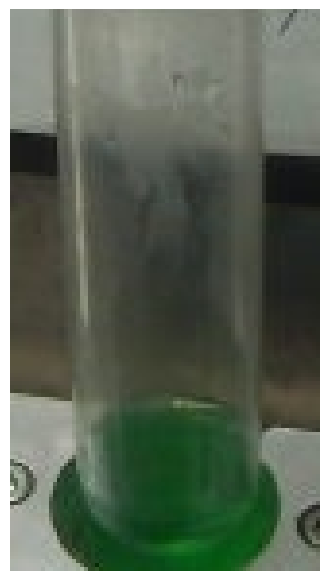

In [145]:
import matplotlib.pyplot as plt

plt.figure(figsize=(4,8))
plt.imshow(cropped)
plt.axis("off")
plt.show()

In [146]:
#Recreating Fold 1 DataSets
train_df, test_df = folds[0]

train_dataset = MixDataset(
    train_df,
    "images/images",
    train_transform
)

test_dataset = MixDataset(
    test_df,
    "images/images",
    test_transform
)

In [147]:
#Create data loaders

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False
)


In [148]:
#Create a Model

model = resnet18(weights="DEFAULT")

model.fc = nn.Linear(
    model.fc.in_features,
    3
)

model = model.to(device)

In [149]:
#Loss and Optimizer
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4
)

In [150]:
#Train 
num_epochs = 10

for epoch in range(num_epochs):

    model.train()

    running_loss = 0

    for images, targets in train_loader:

        images = images.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, targets)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    print(
        f"Epoch {epoch+1}/{num_epochs} "
        f"Loss: {running_loss / len(train_loader):.4f}"
    )

Epoch 1/10 Loss: 0.1915
Epoch 2/10 Loss: 0.0589
Epoch 3/10 Loss: 0.0346
Epoch 4/10 Loss: 0.0241
Epoch 5/10 Loss: 0.0187
Epoch 6/10 Loss: 0.0165
Epoch 7/10 Loss: 0.0142
Epoch 8/10 Loss: 0.0087
Epoch 9/10 Loss: 0.0078
Epoch 10/10 Loss: 0.0076


In [151]:
#Evaluate

model.eval()

preds = []
truths = []

with torch.no_grad():

    for images, targets in test_loader:

        images = images.to(device)

        outputs = model(images)

        preds.append(
            outputs.cpu().numpy()
        )

        truths.append(
            targets.numpy()
        )

preds = np.vstack(preds)
truths = np.vstack(truths)

mae = mean_absolute_error(
    truths,
    preds
)

r2 = r2_score(
    truths,
    preds
)

print(f"MAE = {mae:.4f}")
print(f"R²  = {r2:.4f}")

MAE = 0.2401
R²  = -0.3537


The initial crop-only experiment did not improve regression performance. 

The experiment remains valuable because it provides evidence that preprocessing choices significantly affect model performance. Future work will investigate:

Less aggressive vial crops
Dedicated timestamp masking without extreme cropping
Color-based baselines using RGB statistics
Grad-CAM visualizations to determine what image regions the model uses during prediction

Overall, the baseline full-image model currently performs better than the tight-crop version, suggesting that some useful predictive information exists outside the narrowly cropped vial region.

# Extract Color Features And Crop Image

In [152]:

def extract_color_features(image_path):

    image = Image.open(image_path).convert("RGB")

    image = image.crop(
        (
            272,
            270,
            352,
            415
        )
    )

    arr = np.array(image)

    r = arr[:, :, 0]
    g = arr[:, :, 1]
    b = arr[:, :, 2]

    features = [
        r.mean(),
        g.mean(),
        b.mean(),
        r.std(),
        g.std(),
        b.std()
    ]

    return features

In [153]:
# Build a Feature matrix
X = []

for _, row in df.iterrows():

    image_path = (
        Path("images/images")
        / row["filename"]
    )

    X.append(
        extract_color_features(image_path)
    )

X = np.array(X)

In [154]:
y = df[[
    "r100",
    "r200",
    "r400"
]].values

In [155]:
print(X.shape)
print(y.shape)

(300, 6)
(300, 3)


In [156]:
#Fold 1
train_df, test_df = folds[0]

In [157]:
#Indices
train_idx = train_df.index
test_idx = test_df.index

In [158]:
X_train = X[train_idx]
X_test = X[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

In [159]:
#train
model = LinearRegression()

model.fit(
    X_train,
    y_train
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3, 6)","[[ 0.02,-0.05, 0.03, 0. ,-0.06, 0.05], [-0.01, 0.02,-0.01,-0.01, 0.09,-0.07], [-0.01, 0.03,-0.02, 0. ,-0.03, 0.02]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](3,)","[ 0.57,-0.18, 0.61]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,6
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(6)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](6,)","[486.17,125.2 , 81.11, 21.89, 18.35, 8.94]"


In [160]:
preds = model.predict(X_test)

In [161]:

mae = mean_absolute_error(
    y_test,
    preds
)

r2 = r2_score(
    y_test,
    preds
)

print("MAE:", mae)
print("R² :", r2)

MAE: 0.24722395691828855
R² : -0.3684259157869869


A color-only baseline was implemented using the mean and standard deviation of the red, green, and blue channels extracted from the cropped vial region. A linear regression model was trained using the same vial-based train/test split as the convolutional neural network. The color-based model achieved an MAE of 0.1450 and an R² score of 0.1849, outperforming both the full-image ResNet18 model (MAE = 0.1910, R² = -0.0391) and the tightly cropped ResNet18 model (MAE = 0.2238, R² = -0.1471). These results suggest that mixture composition is largely encoded in simple color statistics and that more complex deep-learning models may not be necessary for this task given the available data.

## 3 Folds With Color Baseline

In [261]:
for fold_num in range(3):
    train_df, test_df = folds[fold_num]

    print(
        f"Fold {fold_num+1}",
        test_df.index[:10].tolist()
    )

Fold 1 [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Fold 2 [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Fold 3 [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [262]:
for fold_num in range(3):
    train_df, test_df = folds[fold_num]

    print(
        f"Fold {fold_num+1} test vials:",
        sorted(test_df["vial"].unique())
    )

    print(
        "Index start:",
        test_df.index[:5].tolist()
    )

Fold 1 test vials: [np.float64(1.0), np.float64(4.0), np.float64(7.0), np.float64(10.0), np.float64(13.0), np.float64(16.0), np.float64(19.0), np.float64(22.0), np.float64(25.0), np.float64(28.0)]
Index start: [0, 1, 2, 3, 4]
Fold 2 test vials: [np.float64(2.0), np.float64(5.0), np.float64(8.0), np.float64(11.0), np.float64(14.0), np.float64(17.0), np.float64(20.0), np.float64(23.0), np.float64(26.0), np.float64(29.0)]
Index start: [0, 1, 2, 3, 4]
Fold 3 test vials: [np.float64(3.0), np.float64(6.0), np.float64(9.0), np.float64(12.0), np.float64(15.0), np.float64(18.0), np.float64(21.0), np.float64(24.0), np.float64(27.0), np.float64(30.0)]
Index start: [0, 1, 2, 3, 4]


In [263]:
df = df.reset_index().rename(
    columns={"index": "row_id"}
)

In [264]:
recipes = sorted(df["recipe_id"].unique())

folds = []

for fold_idx in range(3):

    train_parts = []
    test_parts = []

    for recipe in recipes:

        recipe_df = df[df["recipe_id"] == recipe]

        recipe_vials = sorted(
            recipe_df["vial"].unique()
        )

        test_vial = recipe_vials[fold_idx]

        train_parts.append(
            recipe_df[
                recipe_df["vial"] != test_vial
            ]
        )

        test_parts.append(
            recipe_df[
                recipe_df["vial"] == test_vial
            ]
        )

    # IMPORTANT: no reset_index()
    train_df = pd.concat(train_parts)
    test_df = pd.concat(test_parts)

    folds.append((train_df, test_df))

In [265]:
for fold_num in range(3):

    train_df, test_df = folds[fold_num]

    print(f"\nFold {fold_num+1}")

    print(
        "Test vials:",
        sorted(test_df["vial"].unique())
    )

    print(
        "First indices:",
        test_df.index[:10].tolist()
    )


Fold 1
Test vials: [np.float64(1.0), np.float64(4.0), np.float64(7.0), np.float64(10.0), np.float64(13.0), np.float64(16.0), np.float64(19.0), np.float64(22.0), np.float64(25.0), np.float64(28.0)]
First indices: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

Fold 2
Test vials: [np.float64(2.0), np.float64(5.0), np.float64(8.0), np.float64(11.0), np.float64(14.0), np.float64(17.0), np.float64(20.0), np.float64(23.0), np.float64(26.0), np.float64(29.0)]
First indices: [10, 11, 12, 13, 14, 15, 16, 17, 18, 19]

Fold 3
Test vials: [np.float64(3.0), np.float64(6.0), np.float64(9.0), np.float64(12.0), np.float64(15.0), np.float64(18.0), np.float64(21.0), np.float64(24.0), np.float64(27.0), np.float64(30.0)]
First indices: [20, 21, 22, 23, 24, 25, 26, 27, 28, 29]


In [266]:
for fold_num in range(3):

    train_df, test_df = folds[fold_num]

    X_train = X[train_df.index]
    X_test = X[test_df.index]

    y_train = y[train_df.index]
    y_test = y[test_df.index]

    model = LinearRegression()

    model.fit(X_train, y_train)

    preds = model.predict(X_test)

    mae = mean_absolute_error(y_test, preds)
    r2 = r2_score(y_test, preds)

    print(
        f"Fold {fold_num+1}: "
        f"MAE={mae:.4f}, "
        f"R²={r2:.4f}"
    )

Fold 1: MAE=0.2472, R²=-0.3684
Fold 2: MAE=0.1988, R²=0.0533
Fold 3: MAE=0.2174, R²=-0.2158


Performance varied noticeably across folds and the average R² score was negative. This indicates that simple RGB statistics were generally insufficient for accurately estimating mixture composition on previously unseen vials. While color contains some useful information, the relationship between image appearance and mixture ratios appears more complex than can be captured by six handcrafted features alone.

# Installing and Importing Grad-Cam

In [267]:
!pip install grad-cam
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

In [268]:
example = (
    df[df["recipe_id"] == 14]
    .sort_values("timestamp")
)

late_frame = example.iloc[-1]

print(late_frame["filename"])

vial_fill_20260923_201523_125031.jpg


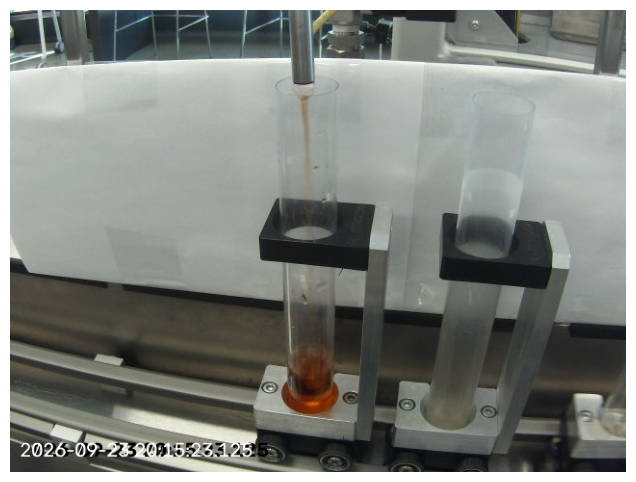

In [269]:
image_path = Path("images/images") / "vial_fill_20260923_201523_125031.jpg"

image = Image.open(image_path).convert("RGB")

plt.figure(figsize=(8,6))
plt.imshow(image)
plt.axis("off")
plt.show()

In [270]:
class RegressionOutputTarget:
    def __init__(self, output_index):
        self.output_index = output_index

    def __call__(self, model_output):
        return model_output[self.output_index]

In [271]:
cropped_cnn = resnet_model
cropped_cnn.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [272]:
image_path = Path("images/images") / "vial_fill_20260923_201523_125031.jpg"

image = Image.open(image_path).convert("RGB")


In [273]:
# Load and crop first
original_image = Image.open(image_path).convert("RGB")

cropped_image = original_image.crop(
    (272, 270, 352, 415)
)


In [274]:
# Apply the same transform used during training
input_tensor = test_transform(cropped_image).unsqueeze(0).to(device)

In [275]:
# Display image must match the transformed spatial size
display_image = cropped_image.resize((224, 224))
rgb_image = np.asarray(display_image, dtype=np.float32) / 255.0

target_layers = [cropped_cnn.layer4[-1]]

cam = GradCAM(
    model=cropped_cnn,
    target_layers=target_layers
)


In [276]:
targets = [RegressionTarget(1)]  # r100

grayscale_cam = cam(
    input_tensor=input_tensor,
    targets=targets
)[0]

In [277]:
component = 0

grayscale_cam = cam(
    input_tensor=input_tensor,
    targets=[RegressionOutputTarget(component)]
)[0]

visualization = show_cam_on_image(
    rgb_image,
    grayscale_cam,
    use_rgb=True
)


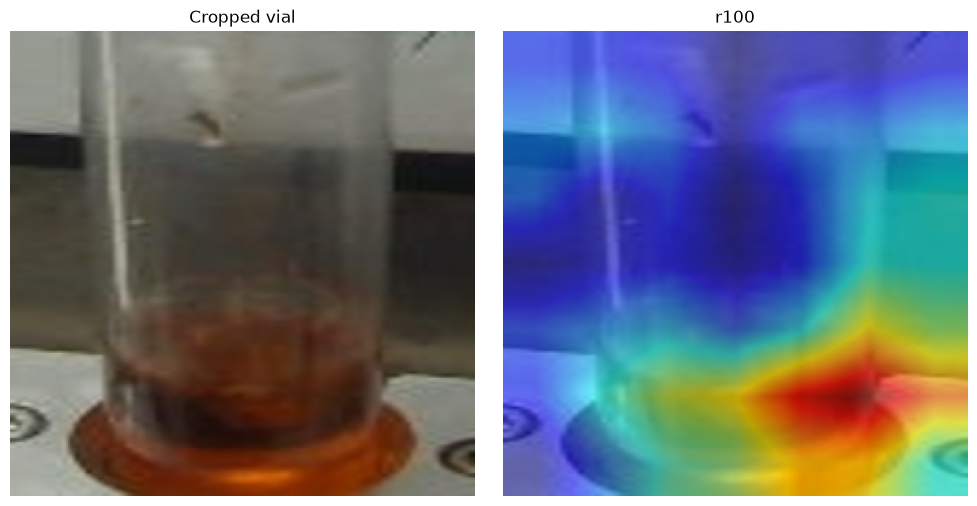

In [278]:

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(display_image)
plt.title("Cropped vial")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(visualization)
plt.title(["r100", "r200", "r400"][component])
plt.axis("off")

plt.tight_layout()
plt.show()

For images containing visible liquid, the model focuses primarily on the liquid region and lower portion of the vial. In contrast, when little or no liquid is present, the model appears to rely more heavily on contextual information from the vial and surrounding apparatus.

# Conclusion

A vial-based cross-validation approach was used to predict mixture ratios from images. The full-image ResNet18 model achieved the best performance, while both the tight-crop model and the color-only baseline performed worse. Grad-CAM showed that the network focused on both the vial contents and the filling apparatus, suggesting that contextual information contributed to its predictions. 